<a href="https://colab.research.google.com/github/pkucheryanov-cpu/IAD-TimeSeries-ARIMA/blob/main/time_series_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

        Дата  Період_t  Середній_бал_Y
0 2026-10-01         1            66.0
1 2026-10-02         2            67.2
2 2026-10-03         3            69.5
3 2026-10-04         4            69.8
4 2026-10-05         5            63.8
... усього спостережень: 100

КРОК 1. ВІЗУАЛІЗАЦІЯ ЧАСОВОГО РЯДУ ТА ЛІНІЇ ТРЕНДУ


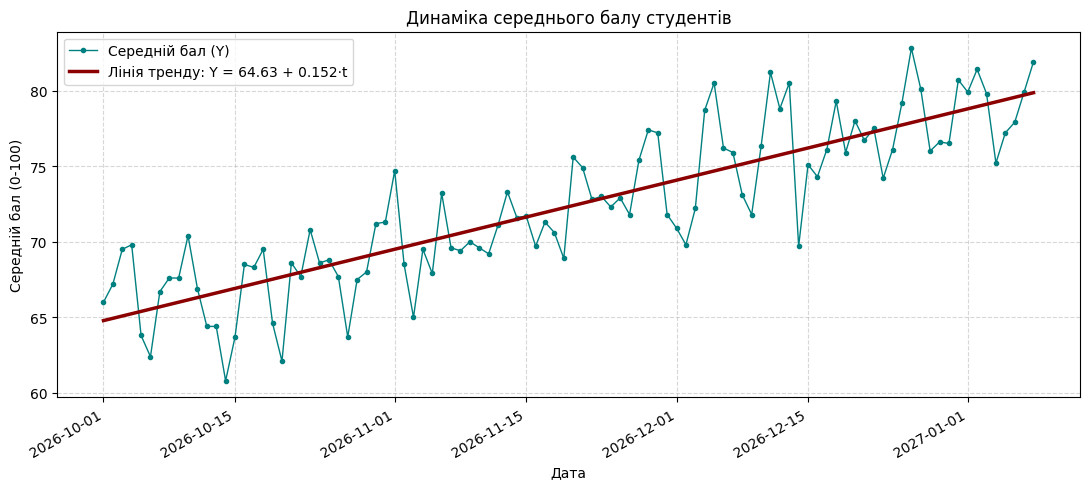

Рівняння лінійного тренду: Y = 64.63 + 0.1522·t
Середній приріст за добу: 0.1522 бала; за весь період (100 діб): 15.07 бала
R² = 0.735; p-значення для кутового коефіцієнта = 5.33e-30

ВИСНОВОК: на графіку й за результатами регресії спостерігається статистично значущий висхідний (зростання) тренд (p < 0.05). Крім тренду, на графіку помітні регулярні коливання навколо лінії тренду, які свідчать про наявність сезонної складової.

КРОК 2. КРИТЕРІЙ «ВИСХІДНИХ І НИЗХІДНИХ» СЕРІЙ
Послідовність знаків (перші 50 із 97):
+++--+++---++-+--+-+-+--+++++--+-+--+--++-+-+--+--...

Кількість «+»: 50, кількість «-»: 47, виключено нульових різниць: 2
Ефективна довжина ряду n = 98
Загальна кількість серій            v   = 59
Довжина найдовшої серії             tau = 5

Критична кількість серій: v > 56  ->  59 > 56  : виконується
Критична довжина серії:   tau <= 6  ->  5 <= 6 : виконується

ФІНАЛЬНИЙ ВЕРДИКТ: Тенденція в часовому ряду відсутня
(обидві нерівності виконуються, гіпотезу про випадковість ряду 

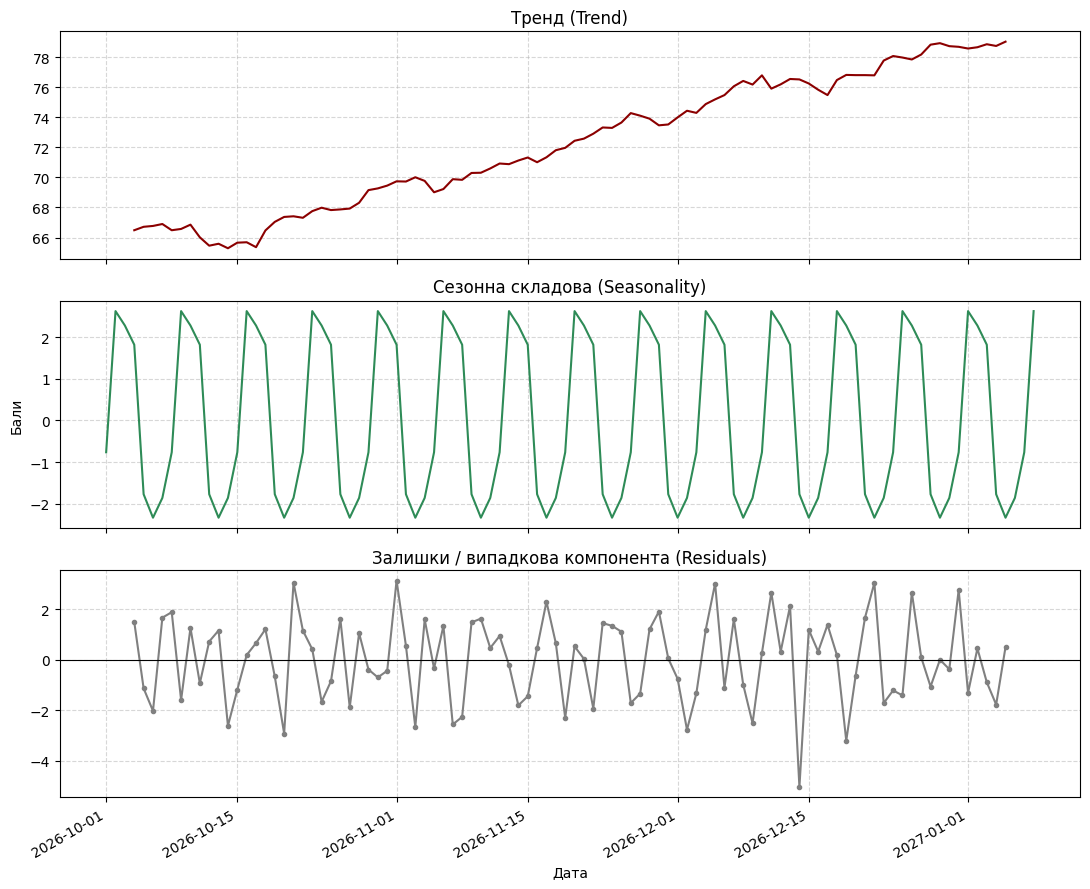

Тренд: від 66.49 до 79.04 бала (зміна +12.56). Перші та останні 3 значення тренду не обчислюються (втрата на краях через згладжування ковзним середнім).
Сезонність: розмах за тиждень = 4.97 бала (від -2.34 до +2.63); сезонний цикл повторюється кожні 7 діб.
Залишки: середнє = -0.011, стандартне відхилення = 1.676, кількість значень = 94.

ВИСНОВОК: ряд успішно розкладено на тренд (стійке зростання), тижневу сезонність і випадкову компоненту. Коректність розкладу перевіряється в кроці 4.

КРОК 4. АВТОКОРЕЛЯЦІЯ ВИПАДКОВОЇ КОМПОНЕНТИ (залишків)


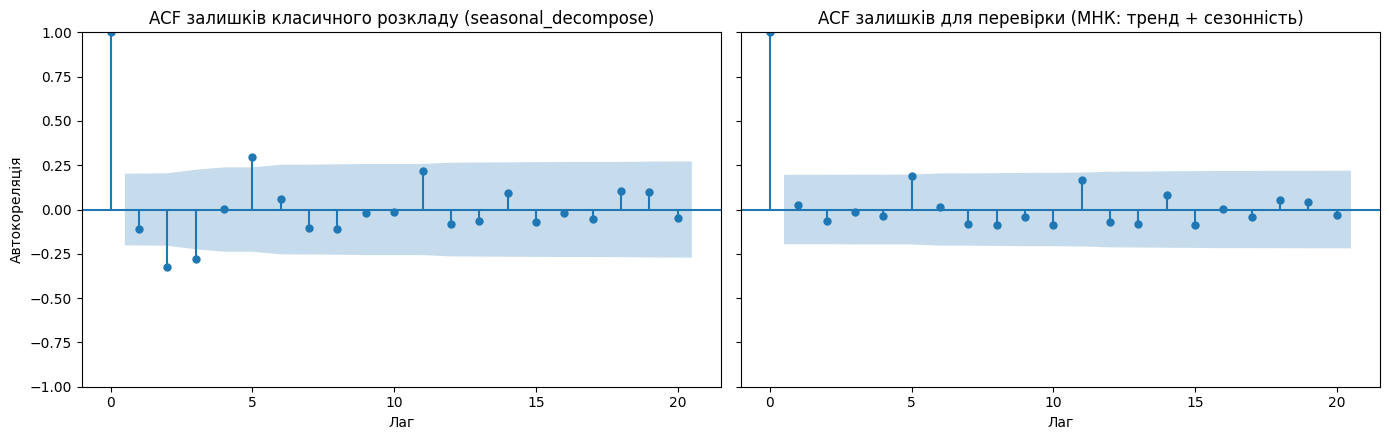


--- Залишки класичного розкладу (seasonal_decompose) ---
Кількість значень: 94; межі 95% довірчого інтервалу: ±0.202
Лаги поза інтервалом (з 20): [2, 3, 5, 11] (при білому шумі очікується ≈ 1)
Найбільша за модулем автокореляція: 0.323
Тест Люнга–Бокса (lag = 10): Q = 30.926, p-значення = 0.0006

--- Залишки МНК-моделі (лінійний тренд + тижневі індикатори) ---
Кількість значень: 100; межі 95% довірчого інтервалу: ±0.196
Лаги поза інтервалом (з 20): немає (при білому шумі очікується ≈ 1)
Найбільша за модулем автокореляція: 0.187
Тест Люнга–Бокса (lag = 10): Q = 7.144, p-значення = 0.7118

ВИСНОВОК:
Залишки класичного розкладу формально не є білим шумом (p = 0.0006, лаги поза інтервалом: [2, 3, 5, 11]). Проте ця автокореляція є наслідком самого методу: тренд оцінюється ковзним середнім, яке згладжує випадкову складову й вносить у залишки штучні залежності між сусідніми точками (ефект Слуцького–Юла).
Підтвердження: після вилучення лінійного тренду та тижневої сезонності регресійним методо

In [ ]:
# -*- coding: utf-8 -*-
"""
Практична робота: аналіз часового ряду «Середній бал студентів»

Кроки:
  1. Візуалізація ряду та лінії тренду
  2. Критерій висхідних і низхідних серій
  3. Розклад ряду на тренд, сезонність, залишки
  4. Автокореляція випадкової компоненти (ACF)

"""

from itertools import groupby

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

ALPHA = 0.05      # рівень значущості для всіх перевірок
PERIOD = 7        # період сезонності (тижнева сезонність)


def header(text):
    """Виводить заголовок кроку в консоль."""
    print("\n" + "=" * 78)
    print(text)
    print("=" * 78)


# ---------------------------------------------------------------------------
# 0. Генерація даних (ваш базовий код без змін)
# ---------------------------------------------------------------------------
def generate_dataset():
    np.random.seed(42)
    days = 100
    dates = pd.date_range(start='2026-10-01', periods=days, freq='D')
    trend = np.linspace(65, 80, days)
    seasonality = 3 * np.sin(2 * np.pi * np.arange(days) / 7)
    random_noise = np.random.normal(0, 2, days)
    average_score = np.clip(np.round(trend + seasonality + random_noise, 1), 0, 100)

    return pd.DataFrame({
        'Дата': dates,
        'Період_t': range(1, days + 1),
        'Середній_бал_Y': average_score
    })


# ---------------------------------------------------------------------------
# КРОК 1. Візуалізація початкового ряду та лінії тренду
# ---------------------------------------------------------------------------
def step1_visualize(df):
    header("КРОК 1. ВІЗУАЛІЗАЦІЯ ЧАСОВОГО РЯДУ ТА ЛІНІЇ ТРЕНДУ")

    t = df['Період_t'].to_numpy()
    y = df['Середній_бал_Y'].to_numpy()

    # Лінійний тренд методом найменших квадратів: Y = a + b*t
    reg = stats.linregress(t, y)
    trend_line = reg.intercept + reg.slope * t

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(df['Дата'], y, marker='o', markersize=3, linewidth=1,
            color='teal', label='Середній бал (Y)')
    ax.plot(df['Дата'], trend_line, color='darkred', linewidth=2.5,
            label=f'Лінія тренду: Y = {reg.intercept:.2f} + {reg.slope:.3f}·t')
    ax.set_title('Динаміка середнього балу студентів')
    ax.set_xlabel('Дата')
    ax.set_ylabel('Середній бал (0-100)')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.savefig('fig1_time_series.png', dpi=150)
    plt.show()

    # --- Текстовий висновок ---
    growth = trend_line[-1] - trend_line[0]
    print(f"Рівняння лінійного тренду: Y = {reg.intercept:.2f} + {reg.slope:.4f}·t")
    print(f"Середній приріст за добу: {reg.slope:.4f} бала; "
          f"за весь період ({len(df)} діб): {growth:.2f} бала")
    print(f"R² = {reg.rvalue ** 2:.3f}; p-значення для кутового коефіцієнта = {reg.pvalue:.2e}")

    if reg.pvalue < ALPHA:
        direction = "висхідний (зростання)" if reg.slope > 0 else "спадний (зниження)"
        print(f"\nВИСНОВОК: на графіку й за результатами регресії спостерігається "
              f"статистично значущий {direction} тренд (p < {ALPHA}). "
              f"Крім тренду, на графіку помітні регулярні коливання навколо лінії "
              f"тренду, які свідчать про наявність сезонної складової.")
    else:
        print("\nВИСНОВОК: лінійний тренд статистично незначущий; "
              "суттєвої тенденції на графіку не виявлено.")
    return reg


# ---------------------------------------------------------------------------
# КРОК 2. Критерій «висхідних і низхідних» серій
# ---------------------------------------------------------------------------
def tau_critical(n):
    """Табличне значення τ0(n) – допустима довжина найдовшої серії."""
    if n <= 26:
        return 5
    if n <= 153:
        return 6
    if n <= 1170:
        return 7
    raise ValueError("Для n > 1170 потрібна розширена таблиця критичних значень")


def runs_up_down_test(y):
    """
    Критерій висхідних і низхідних серій (реалізація з нуля).

    1) Порівнюємо кожне Y_t з Y_(t-1): різниця > 0 -> «+», різниця < 0 -> «-».
       Однакові сусідні значення (різниця = 0) виключаються з розгляду,
       при цьому ефективна довжина ряду n зменшується.
    2) Серія – послідовність однакових знаків підряд.
       v   – загальна кількість серій;
       tau – довжина найдовшої серії.
    3) Гіпотеза H0 «тенденції немає» приймається, якщо одночасно виконано:
          v > [ (2n - 1)/3 - 1.96 * sqrt((16n - 29)/90) ]
          tau <= τ0(n)
       Якщо хоча б одна нерівність порушена – тенденція присутня.
       (1.96 – квантиль нормального розподілу для рівня значущості 5%)
    """
    y = np.asarray(y, dtype=float)

    # 1. Послідовність знаків
    diffs = np.diff(y)
    n_ties = int(np.sum(diffs == 0))
    signs = np.sign(diffs[diffs != 0]).astype(int)
    n = len(signs) + 1                      # ефективна довжина ряду

    # 2. Кількість серій та довжина найдовшої серії
    run_lengths = [len(list(g)) for _, g in groupby(signs)]
    v = len(run_lengths)
    tau = max(run_lengths)

    # 3. Критичні значення
    v_crit = int(np.floor((2 * n - 1) / 3 - 1.96 * np.sqrt((16 * n - 29) / 90)))
    tau_crit = tau_critical(n)

    cond_v = v > v_crit
    cond_tau = tau <= tau_crit
    no_trend = cond_v and cond_tau

    return {
        'signs': signs, 'n': n, 'n_ties': n_ties,
        'n_plus': int(np.sum(signs > 0)), 'n_minus': int(np.sum(signs < 0)),
        'v': v, 'tau': tau, 'v_crit': v_crit, 'tau_crit': tau_crit,
        'cond_v': cond_v, 'cond_tau': cond_tau, 'no_trend': no_trend,
    }


def step2_runs_test(df):
    header("КРОК 2. КРИТЕРІЙ «ВИСХІДНИХ І НИЗХІДНИХ» СЕРІЙ")
    y = df['Середній_бал_Y'].to_numpy()
    r = runs_up_down_test(y)

    sign_str = ''.join('+' if s > 0 else '-' for s in r['signs'])
    print(f"Послідовність знаків (перші 50 із {len(r['signs'])}):")
    print(sign_str[:50] + ('...' if len(sign_str) > 50 else ''))
    print(f"\nКількість «+»: {r['n_plus']}, кількість «-»: {r['n_minus']}, "
          f"виключено нульових різниць: {r['n_ties']}")
    print(f"Ефективна довжина ряду n = {r['n']}")
    print(f"Загальна кількість серій            v   = {r['v']}")
    print(f"Довжина найдовшої серії             tau = {r['tau']}")

    print(f"\nКритична кількість серій: v > {r['v_crit']}  ->  "
          f"{r['v']} > {r['v_crit']}  : {'виконується' if r['cond_v'] else 'НЕ виконується'}")
    print(f"Критична довжина серії:   tau <= {r['tau_crit']}  ->  "
          f"{r['tau']} <= {r['tau_crit']} : {'виконується' if r['cond_tau'] else 'НЕ виконується'}")

    if r['no_trend']:
        print("\nФІНАЛЬНИЙ ВЕРДИКТ: Тенденція в часовому ряду відсутня")
        print("(обидві нерівності виконуються, гіпотезу про випадковість ряду "
              "не відхилено на рівні значущості 5%).")
    else:
        print("\nФІНАЛЬНИЙ ВЕРДИКТ: Тенденція в часовому ряду присутня")
        failed = []
        if not r['cond_v']:
            failed.append("кількість серій v замала")
        if not r['cond_tau']:
            failed.append("найдовша серія tau завелика")
        print(f"(порушено умову: {', '.join(failed)}; гіпотезу про відсутність "
              f"тенденції відхилено на рівні значущості 5%).")

    # --- Додаткова перевірка та узгодження з кроком 1 ---
    t = df['Період_t'].to_numpy()
    tau_k, p_k = stats.kendalltau(t, y)         # аналог тесту Манна–Кендалла
    print(f"\nДодаткова перевірка (тест Кендалла «час – значення»): "
          f"tau = {tau_k:.3f}, p-значення = {p_k:.2e}")

    if r['no_trend'] and p_k < ALPHA:
        mean_step = (y[-1] - y[0]) / (len(y) - 1)
        noise_step = np.std(np.diff(y))
        print("\nУЗГОДЖЕННЯ З КРОКОМ 1: результати критерію серій та регресії суперечать "
              "одне одному, і це пояснюється обмеженою потужністю критерію серій.")
        print(f"Критерій враховує лише ЗНАКИ сусідніх різниць, а середній добовий приріст "
              f"тренду ({mean_step:.2f} бала) значно менший за типову добову зміну ряду "
              f"(стандартне відхилення різниць {noise_step:.2f} бала через шум і сезонність). "
              f"Тому знаки чергуються майже як у випадковому ряді: v = {r['v']} лише трохи "
              f"перевищує критичне значення {r['v_crit']}.")
        print("Для надійного висновку слід спиратися на сукупність методів: регресійний "
              "тест (крок 1) та тест Кендалла підтверджують наявність висхідного тренду.")
    elif (not r['no_trend']) and p_k < ALPHA:
        print("\nУЗГОДЖЕННЯ З КРОКОМ 1: критерій серій, регресія та тест Кендалла "
              "дають однаковий висновок – тенденція присутня.")


# ---------------------------------------------------------------------------
# КРОК 3. Розклад ряду на тренд, сезонність і залишки
# ---------------------------------------------------------------------------
def step3_decompose(df):
    header("КРОК 3. КЛАСИЧНИЙ ДЕКОМПОЗИЦІЙНИЙ АНАЛІЗ (адитивна модель, period=7)")

    series = pd.Series(df['Середній_бал_Y'].to_numpy(),
                       index=pd.DatetimeIndex(df['Дата']), name='Середній бал')
    result = seasonal_decompose(series, model='additive', period=PERIOD)

    components = [
        (result.trend, 'Тренд (Trend)', 'darkred'),
        (result.seasonal, 'Сезонна складова (Seasonality)', 'seagreen'),
        (result.resid, 'Залишки / випадкова компонента (Residuals)', 'gray'),
    ]
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
    for ax, (comp, title, color) in zip(axes, components):
        ax.plot(comp.index, comp.values, color=color, linewidth=1.5,
                marker='o' if 'Залишки' in title else None, markersize=3)
        ax.set_title(title)
        ax.grid(True, linestyle='--', alpha=0.5)
    axes[1].set_ylabel('Бали')
    axes[2].axhline(0, color='black', linewidth=0.8)
    axes[2].set_xlabel('Дата')
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.savefig('fig2_decomposition.png', dpi=150)
    plt.show()

    # --- Текстові висновки ---
    trend = result.trend.dropna()
    seas_cycle = result.seasonal.iloc[:PERIOD]
    resid = result.resid.dropna()

    print(f"Тренд: від {trend.iloc[0]:.2f} до {trend.iloc[-1]:.2f} бала "
          f"(зміна {trend.iloc[-1] - trend.iloc[0]:+.2f}). "
          f"Перші та останні {PERIOD // 2} значення тренду не обчислюються "
          f"(втрата на краях через згладжування ковзним середнім).")
    print(f"Сезонність: розмах за тиждень = {seas_cycle.max() - seas_cycle.min():.2f} бала "
          f"(від {seas_cycle.min():+.2f} до {seas_cycle.max():+.2f}); "
          f"сезонний цикл повторюється кожні {PERIOD} діб.")
    print(f"Залишки: середнє = {resid.mean():+.3f}, "
          f"стандартне відхилення = {resid.std():.3f}, "
          f"кількість значень = {len(resid)}.")
    print("\nВИСНОВОК: ряд успішно розкладено на тренд (стійке зростання), "
          "тижневу сезонність і випадкову компоненту. "
          "Коректність розкладу перевіряється в кроці 4.")
    return resid


# ---------------------------------------------------------------------------
# КРОК 4. Автокореляція випадкової компоненти
# ---------------------------------------------------------------------------
def regression_residuals(df):
    """
    Альтернативні залишки для перевірки: МНК-модель «лінійний тренд + тижневі
    сезонні індикатори». На відміну від класичного розкладу вона не використовує
    ковзне середнє, а отже не вносить штучної автокореляції в залишки.
    """
    t = df['Період_t'].to_numpy(dtype=float)
    y = df['Середній_бал_Y'].to_numpy(dtype=float)
    season = np.column_stack([(t % PERIOD == k).astype(float) for k in range(1, PERIOD)])
    X = np.column_stack([np.ones_like(t), t, season])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return pd.Series(y - X @ beta, index=pd.DatetimeIndex(df['Дата']))


def white_noise_check(resid, max_lag=20, lb_lags=10):
    """Кількісна перевірка залишків: лаги поза інтервалом + тест Люнга–Бокса."""
    n = len(resid)
    bound = 1.96 / np.sqrt(n)
    acf_values = acf(resid, nlags=max_lag, fft=False)
    outside = [lag for lag in range(1, max_lag + 1) if abs(acf_values[lag]) > bound]
    expected = ALPHA * max_lag                  # очікувана кількість випадкових виходів
    lb = acorr_ljungbox(resid, lags=[lb_lags], return_df=True)
    lb_stat, lb_p = float(lb['lb_stat'].iloc[0]), float(lb['lb_pvalue'].iloc[0])
    is_white = (lb_p > ALPHA) and (len(outside) <= max(1, round(expected)))
    return {'n': n, 'bound': bound, 'outside': outside, 'expected': expected,
            'lb_stat': lb_stat, 'lb_p': lb_p, 'is_white': is_white,
            'max_abs': float(np.max(np.abs(acf_values[1:])))}


def print_check(title, c, max_lag, lb_lags):
    print(f"\n--- {title} ---")
    print(f"Кількість значень: {c['n']}; межі 95% довірчого інтервалу: ±{c['bound']:.3f}")
    print(f"Лаги поза інтервалом (з {max_lag}): "
          f"{c['outside'] if c['outside'] else 'немає'} "
          f"(при білому шумі очікується ≈ {c['expected']:.0f})")
    print(f"Найбільша за модулем автокореляція: {c['max_abs']:.3f}")
    print(f"Тест Люнга–Бокса (lag = {lb_lags}): Q = {c['lb_stat']:.3f}, "
          f"p-значення = {c['lb_p']:.4f}")


def step4_acf(resid, alt_resid, max_lag=20, lb_lags=10):
    header("КРОК 4. АВТОКОРЕЛЯЦІЯ ВИПАДКОВОЇ КОМПОНЕНТИ (залишків)")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    plot_acf(resid, lags=max_lag, alpha=ALPHA, ax=axes[0])
    axes[0].set_title('ACF залишків класичного розкладу (seasonal_decompose)')
    plot_acf(alt_resid, lags=max_lag, alpha=ALPHA, ax=axes[1])
    axes[1].set_title('ACF залишків для перевірки (МНК: тренд + сезонність)')
    for ax in axes:
        ax.set_xlabel('Лаг')
    axes[0].set_ylabel('Автокореляція')
    plt.tight_layout()
    plt.savefig('fig3_acf_residuals.png', dpi=150)
    plt.show()

    c1 = white_noise_check(resid, max_lag, lb_lags)
    c2 = white_noise_check(alt_resid, max_lag, lb_lags)
    print_check("Залишки класичного розкладу (seasonal_decompose)", c1, max_lag, lb_lags)
    print_check("Залишки МНК-моделі (лінійний тренд + тижневі індикатори)", c2, max_lag, lb_lags)

    print("\nВИСНОВОК:")
    if c1['is_white']:
        print(f"Автокореляція залишків статистично незначуща (p = {c1['lb_p']:.3f} > {ALPHA}), "
              "лаги лежать у межах довірчого інтервалу. Залишки є білим шумом, тобто "
              "тренд і сезонність виділено коректно, розклад ряду виконано правильно.")
    elif c2['is_white']:
        print(f"Залишки класичного розкладу формально не є білим шумом "
              f"(p = {c1['lb_p']:.4f}, лаги поза інтервалом: {c1['outside']}). "
              "Проте ця автокореляція є наслідком самого методу: тренд оцінюється ковзним "
              "середнім, яке згладжує випадкову складову й вносить у залишки штучні "
              "залежності між сусідніми точками (ефект Слуцького–Юла).")
        print(f"Підтвердження: після вилучення лінійного тренду та тижневої сезонності "
              f"регресійним методом залишки вже є білим шумом "
              f"(p = {c2['lb_p']:.3f} > {ALPHA}, лагів поза інтервалом немає). "
              "Отже, закономірні компоненти (тренд і тижнева сезонність) виділено "
              "коректно, а у випадковій компоненті невиділеної структури не залишилося.")
    else:
        print(f"У залишках обох розкладів зберігається автокореляція "
              f"(p = {c1['lb_p']:.4f} та {c2['lb_p']:.4f}). Залишки не є білим шумом: "
              "у ряді лишилася невиділена закономірність, тому розклад слід уточнити "
              "(інший період сезонності, нелінійний тренд, мультиплікативна модель).")


# ---------------------------------------------------------------------------
def main():
    df = generate_dataset()
    print(df.head())
    print(f"... усього спостережень: {len(df)}")

    step1_visualize(df)
    step2_runs_test(df)
    resid = step3_decompose(df)
    step4_acf(resid, regression_residuals(df))


if __name__ == '__main__':
    main()